# TuCaserito — Modelo de predicción de Ingreso y Egreso diario (bodegas)
**Hackathon BBVA 2026 — Equipo 7**
**Scope: IA / ML / analítica (25%) + Datos sintéticos y evidencia (15%)**

Este notebook:
1. Simula un dataset sintético realista de **miles de bodegueros** (serie temporal diaria).
2. Entrena **LightGBM (quantile regression)** para predecir **ingreso** y **egreso** diario por bodega.
3. Evalúa con backtesting temporal (train/test por fecha, no random split — evita fuga de información).
4. Expone métricas, intervalos de incertidumbre (P10/P50/P90) y feature importance, listos para integrarse al endpoint `/api/v1` del MVP (ver `contract.md`).

> Nota de reproducibilidad: todo corre con `random_state` fijo. No usa data real de BBVA (regla del reto).


In [1]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.max_columns", 50)


## 1. Simulación de datos sintéticos

Se simulan **N_BODEGAS bodegueros** (pymes no bancarizadas) durante **N_DIAS días** (~18 meses), con:
- **Heterogeneidad entre negocios**: tamaño (ingreso base), ubicación (urbano/periurbano/rural), rubro (abarrotes/bebidas/mixto).
- **Estacionalidad semanal** (fin de semana = más venta) y **mensual** (quincena/fin de mes = más consumo).
- **Shocks aleatorios**: días de quiebre de stock, feriados, eventos climáticos.
- **Egresos correlacionados con ingresos** (reposición de mercadería, pago a proveedores) más componentes fijos (alquiler, deuda, impuestos periódicos).
- **Ruido** realista para evitar un problema trivial.

Esto es **data sintética declarada como tal** (no real de BBVA), con supuestos documentados abajo para la justificación de realismo pedida en el reto.


In [2]:
N_BODEGAS = 1200      # "miles de bodegueros" (reducido para training rapido en hackathon)
N_DIAS = 120          # ~4 meses de historia por bodega (reducido para training rapido)
FECHA_INICIO = pd.Timestamp("2024-06-01")

fechas = pd.date_range(FECHA_INICIO, periods=N_DIAS, freq="D")

# --- Perfil estático de cada bodega (heterogeneidad) ---
# rubro: usa la taxonomía real de la tabla `rubros` del modelo de datos del equipo
# (antes se usaban categorías inventadas que no existían en la BD: abarrotes/bebidas/mixto/panaderia)
rubros = rng.choice(["bodega", "restaurante", "taller", "distribuidora"], size=N_BODEGAS, p=[0.70, 0.15, 0.08, 0.07])
rubro_factor = {"bodega": 1.0, "restaurante": 1.3, "taller": 0.9, "distribuidora": 1.6}

# n_trabajadores reemplaza a "zona": zona en la BD real es texto libre (distrito, ej. "SJL"),
# sin categorías fijas ni regla de mapeo acordada con el equipo de backend. n_trabajadores en
# cambio SÍ existe directo en empresas.n_trabajadores, así que se puede construir con data real.
n_trabajadores = rng.choice([1, 2, 3, 4, 5], size=N_BODEGAS, p=[0.45, 0.25, 0.15, 0.10, 0.05])
trabajador_factor = 1.0 + 0.12 * (n_trabajadores - 1)

ingreso_base = rng.lognormal(mean=5.2, sigma=0.45, size=N_BODEGAS)  # soles/día, cola larga (hay bodegas grandes y chicas)
ingreso_base = ingreso_base * np.array([rubro_factor[r] for r in rubros]) * trabajador_factor

antiguedad_meses = rng.integers(1, 180, size=N_BODEGAS)  # antigüedad del negocio
usa_fiado = rng.random(N_BODEGAS) < 0.65            # % de bodegas que dan fiado
usa_billetera_digital = rng.random(N_BODEGAS) < 0.40  # % que ya usa Yape/Plin

bodegas = pd.DataFrame({
    "bodega_id": [f"BOD-{i:05d}" for i in range(N_BODEGAS)],
    "rubro": rubros,
    "n_trabajadores": n_trabajadores,
    "ingreso_base": ingreso_base,
    "antiguedad_meses": antiguedad_meses,
    "usa_fiado": usa_fiado,
    "usa_billetera_digital": usa_billetera_digital,
})
bodegas.head()


,bodega_id,rubro,n_trabajadores,ingreso_base,antiguedad_meses,usa_fiado,usa_billetera_digital
0,BOD-00000,restaurante,2,353.854648,85,True,False
1,BOD-00001,bodega,2,268.553266,106,True,True
2,BOD-00002,taller,3,198.937101,55,True,False
3,BOD-00003,bodega,3,245.675536,12,False,True
4,BOD-00004,bodega,1,106.342704,102,True,False


In [3]:
# --- Serie temporal por bodega ---
def simular_bodega(row, fechas, rng):
    n = len(fechas)
    dow = fechas.dayofweek.values           # 0=lunes
    dom = fechas.day.values                 # día del mes

    # Estacionalidad semanal: fin de semana (vie-dom) sube venta
    factor_semana = 1.0 + 0.18 * np.isin(dow, [4, 5, 6])

    # Estacionalidad mensual: quincena (14-16) y fin de mes (28-31) suben consumo
    factor_mes = 1.0 + 0.12 * (np.isin(dom, [14, 15, 16]) | (dom >= 28))

    # Tendencia leve de crecimiento/decrecimiento propia del negocio
    tendencia = 1.0 + rng.normal(0, 0.0004, 1)[0] * np.arange(n)

    # Shock de quiebre de stock (ingreso cae fuerte un día aleatorio ~2% de los días)
    shock_quiebre = 1.0 - 0.5 * (rng.random(n) < 0.02)

    # Ruido multiplicativo
    ruido = rng.lognormal(mean=0, sigma=0.15, size=n)

    ingreso = row["ingreso_base"] * factor_semana * factor_mes * tendencia * shock_quiebre * ruido
    ingreso = np.clip(ingreso, 5, None)

    # --- Egreso: reposición de mercadería (correlacionado con ingreso, con rezago) + fijos periódicos ---
    reposicion = 0.55 * np.roll(ingreso, 1) * rng.lognormal(0, 0.1, n)
    reposicion[0] = 0.55 * ingreso[0]

    pago_proveedor_mensual = np.where(dom == 5, row["ingreso_base"] * rng.uniform(1.5, 3.0), 0.0)
    impuesto_mensual = np.where(dom == 15, row["ingreso_base"] * rng.uniform(0.3, 0.6), 0.0)
    alquiler_fijo = row["ingreso_base"] * 0.08 / 30  # prorrateado diario

    egreso = reposicion + pago_proveedor_mensual + impuesto_mensual + alquiler_fijo
    egreso = np.clip(egreso, 2, None)

    return ingreso, egreso

filas = []
for _, row in bodegas.iterrows():
    ingreso, egreso = simular_bodega(row, fechas, rng)
    filas.append(pd.DataFrame({
        "bodega_id": row["bodega_id"],
        "fecha": fechas,
        "ingreso": ingreso,
        "egreso": egreso,
    }))

serie = pd.concat(filas, ignore_index=True)
df = serie.merge(bodegas, on="bodega_id", how="left")
print(df.shape)
df.head()


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 

(144000, 10)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 0=lunes
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\2730544712.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = fechas.dayofweek.values           # 

,bodega_id,fecha,ingreso,egreso,rubro,n_trabajadores,ingreso_base,antiguedad_meses,usa_fiado,usa_billetera_digital
0,BOD-00000,2024-06-01,435.799187,240.633165,restaurante,2,353.854648,85,True,False
1,BOD-00000,2024-06-02,379.030710,260.631449,restaurante,2,353.854648,85,True,False
2,BOD-00000,2024-06-03,356.054106,243.143389,restaurante,2,353.854648,85,True,False
3,BOD-00000,2024-06-04,375.090951,221.531935,restaurante,2,353.854648,85,True,False
4,BOD-00000,2024-06-05,458.379573,1124.291621,restaurante,2,353.854648,85,True,False


### Supuestos y justificación de realismo (para el entregable *Dataset sintético*)

| Supuesto | Justificación |
|---|---|
| Ingreso base log-normal | Las ventas diarias de pymes informales tienen distribución asimétrica con cola larga (pocas bodegas grandes, muchas chicas) — consistente con literatura de microfinanzas |
| Factor rubro (bodega/restaurante/taller/distribuidora) | Usa la taxonomía real de la tabla `rubros` del modelo de datos — reemplaza categorías inventadas que no existían en la BD |
| Factor n_trabajadores | Negocios con más personal mueven más venta; reemplaza a `zona` porque en la BD real es texto libre (distrito) sin categorías ni regla de mapeo definida |
| Estacionalidad semanal (fin de semana +18%) | Patrón reportado en retail de barrio: más consumo viernes-domingo |
| Estacionalidad mensual (quincena / fin de mes) | Coincide con pago de sueldos y planillas en Perú |
| Egreso = reposición rezagada + pagos periódicos | Las bodegas reponen mercadería en función de lo vendido el día anterior (ciclo caja-mercadería), y pagan proveedor/impuestos en fechas fijas del mes |
| Shock de quiebre de stock (2% días) | Evento real y frecuente en pymes sin forecast — es parte del problema que TuCaserito busca resolver |
| Ruido log-normal | Evita que el problema sea trivialmente determinista; obliga al modelo a aprender patrones, no memorizar |

Estos supuestos están documentados aquí explícitamente para la trazabilidad pedida por el reto.


## 2. Feature engineering

Se construyen features típicas de forecasting de series temporales (lags, medias móviles, calendario) replicables con data real una vez el MVP esté en producción (mismas columnas que `transacciones_venta`, `prestamos_proveedor`, `impuestos` del dataset ya definido).


In [4]:
df = df.sort_values(["bodega_id", "fecha"]).reset_index(drop=True)

def add_features(data):
    g = data.groupby("bodega_id")
    for col in ["ingreso", "egreso"]:
        for lag in [1, 7, 14]:
            data[f"{col}_lag{lag}"] = g[col].shift(lag)
        for win in [7, 14, 30]:
            data[f"{col}_media{win}"] = g[col].shift(1).rolling(win).mean().reset_index(drop=True)
            data[f"{col}_std{win}"] = g[col].shift(1).rolling(win).std().reset_index(drop=True)

    data["dow"] = data["fecha"].dt.dayofweek
    data["dom"] = data["fecha"].dt.day
    data["es_finde"] = data["dow"].isin([4, 5, 6]).astype(int)
    data["es_quincena_o_finmes"] = (data["dom"].isin([14, 15, 16]) | (data["dom"] >= 28)).astype(int)
    data["mes"] = data["fecha"].dt.month

    for cat in ["rubro"]:
        data[cat] = data[cat].astype("category")
    data["usa_fiado"] = data["usa_fiado"].astype(int)
    data["usa_billetera_digital"] = data["usa_billetera_digital"].astype(int)
    return data

df = add_features(df)
df = df.dropna().reset_index(drop=True)  # primeros 30 días por bodega sin historia suficiente
print(df.shape)


(108000, 33)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_564\427467665.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["dow"] = data["fecha"].dt.dayofweek


## 2.1 Exportación del dataset sintético

Se exporta la data sintética cruda (serie + perfil de cada bodega) a CSV: `bodegas_ingresos_egresos.csv`. Este es el entregable **Dataset sintético** del reto (diccionario y supuestos ya documentados arriba). El dataset con features (lags, medias móviles, calendario) usado para entrenar se recalcula en segundos con `add_features()` más abajo — no se exporta aparte para no duplicar el entregable.

In [5]:
import os

EXPORT_DIR = "data_sintetica"
os.makedirs(EXPORT_DIR, exist_ok=True)

# Dataset sintético (entregable oficial): serie cruda + perfil de la bodega.
# El dataset con features (lags/medias) se recalcula en segundos con add_features()
# y no se exporta por separado para no duplicar el entregable.
ruta_crudo = os.path.join(EXPORT_DIR, "bodegas_ingresos_egresos.csv")
serie.merge(bodegas, on="bodega_id", how="left").to_csv(ruta_crudo, index=False)

print(f"Dataset sintético: {ruta_crudo} -> {serie.shape[0]:,} filas")

Dataset sintético: data_sintetica\bodegas_ingresos_egresos.csv -> 144,000 filas


## 3. Split temporal (backtesting, no random)

Se separa por **fecha de corte**, no aleatoriamente: el modelo entrena con el pasado y predice el futuro, igual que en producción. Esto evita fuga de información (data leakage) y es más honesto para el jurado.


In [6]:
FECHA_CORTE = df["fecha"].quantile(0.85)
FECHA_CORTE_VAL = df["fecha"].quantile(0.75)  # 10% del rango sirve de validación (early stopping)

train_full = df[df["fecha"] <= FECHA_CORTE]
val = train_full[train_full["fecha"] > FECHA_CORTE_VAL]
train = train_full[train_full["fecha"] <= FECHA_CORTE_VAL]
test = df[df["fecha"] > FECHA_CORTE]

print(f"Corte val/train: {FECHA_CORTE_VAL.date()} | Corte train/test: {FECHA_CORTE.date()}")
print(f"Train: {train.shape[0]:,} filas | Val: {val.shape[0]:,} filas | Test: {test.shape[0]:,} filas")
print(f"Bodegas en train: {train['bodega_id'].nunique():,} | en test: {test['bodega_id'].nunique():,}")


Corte val/train: 2024-09-06 | Corte train/test: 2024-09-15
Train: 81,600 filas | Val: 10,800 filas | Test: 15,600 filas
Bodegas en train: 1,200 | en test: 1,200


In [7]:
# antiguedad_meses SI se deja como feature (antes quedaba excluida por error, pese a aportar señal real)
FEATURES = [c for c in df.columns if c not in
            ["bodega_id", "fecha", "ingreso", "egreso", "ingreso_base"]]
CATEGORICAS = ["rubro"]

X_train, X_val, X_test = train[FEATURES], val[FEATURES], test[FEATURES]
print(f"N features: {len(FEATURES)}")
FEATURES


N features: 28


['rubro',
 'n_trabajadores',
 'antiguedad_meses',
 'usa_fiado',
 'usa_billetera_digital',
 'ingreso_lag1',
 'ingreso_lag7',
 'ingreso_lag14',
 'ingreso_media7',
 'ingreso_std7',
 'ingreso_media14',
 'ingreso_std14',
 'ingreso_media30',
 'ingreso_std30',
 'egreso_lag1',
 'egreso_lag7',
 'egreso_lag14',
 'egreso_media7',
 'egreso_std7',
 'egreso_media14',
 'egreso_std14',
 'egreso_media30',
 'egreso_std30',
 'dow',
 'dom',
 'es_finde',
 'es_quincena_o_finmes',
 'mes']

## 4. Entrenamiento LightGBM — Quantile Regression

Se entrena **un modelo por target (ingreso, egreso) y por cuantil (P10, P50, P90)**.
El cuantil P50 es la predicción puntual; P10/P90 dan un **intervalo de confianza** — clave para que el MVP muestre al bodeguero no solo "cuánto vas a vender" sino el rango de incertidumbre (mejor experiencia y más honesto que un número seco).

**Robustez de entrenamiento** (para que no dependa de fijar `n_estimators` a mano):
- **Early stopping** sobre un set de validación temporal (15–25% más reciente del train) — detiene el entrenamiento cuando el error de validación deja de mejorar.
- **Patience** (`EARLY_STOPPING_ROUNDS`): cuántas rondas sin mejora se toleran antes de parar.
- **Checkpoint / autoguardado**: cada modelo (target × cuantil) se guarda en disco (`modelo/checkpoints/`) apenas termina su entrenamiento, para no perder el trabajo si el proceso se interrumpe (relevante en 8GB RAM, donde el entrenamiento de las 6 combinaciones puede tardar varios minutos).


In [8]:
import os
import time
import joblib

CHECKPOINT_DIR = "checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

PARAMS_BASE = dict(
    objective="quantile",
    n_estimators=2000,       # tope alto: early stopping decide cuándo parar en la práctica
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=30,
    random_state=SEED,
    verbosity=-1,
)

EARLY_STOPPING_ROUNDS = 50   # patience: rondas sin mejora en validación antes de detener

QUANTILES = [0.1, 0.5, 0.9]
TARGETS = ["ingreso", "egreso"]

modelos = {}
tiempos = {}
predicciones_test = test[["bodega_id", "fecha", "ingreso", "egreso"]].copy()

t_total_inicio = time.time()

for target in TARGETS:
    y_train = train[target]
    y_val = val[target]
    for q in QUANTILES:
        checkpoint_path = os.path.join(CHECKPOINT_DIR, f"{target}_p{int(q*100)}.joblib")

        if os.path.exists(checkpoint_path):
            # Autoguardado: si ya existe el checkpoint de una corrida anterior, se reutiliza
            model = joblib.load(checkpoint_path)
            tiempos[(target, q)] = 0.0
            print(f"[{target} P{int(q*100)}] cargado desde checkpoint ({checkpoint_path})")
        else:
            params = {**PARAMS_BASE, "alpha": q}
            model = lgb.LGBMRegressor(**params)

            t0 = time.time()
            model.fit(
                X_train, y_train,
                eval_set=[(X_val, y_val)],
                eval_metric="quantile",
                categorical_feature=CATEGORICAS,
                callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)],
            )
            elapsed = time.time() - t0
            tiempos[(target, q)] = elapsed

            joblib.dump(model, checkpoint_path)  # checkpoint / autoguardado inmediato
            print(f"[{target} P{int(q*100)}] best_iteration={model.best_iteration_} | "
                  f"tiempo={elapsed:.1f}s | guardado en {checkpoint_path}")

        modelos[(target, q)] = model
        col = f"{target}_pred_p{int(q*100)}"
        predicciones_test[col] = model.predict(X_test)

t_total = time.time() - t_total_inicio
print(f"\nTiempo total de entrenamiento: {t_total:.1f}s "
      f"({t_total/60:.1f} min) para {len(modelos)} modelos")

predicciones_test.head()


[ingreso P10] cargado desde checkpoint (checkpoints\ingreso_p10.joblib)
[ingreso P50] cargado desde checkpoint (checkpoints\ingreso_p50.joblib)
[ingreso P90] cargado desde checkpoint (checkpoints\ingreso_p90.joblib)


[egreso P10] cargado desde checkpoint (checkpoints\egreso_p10.joblib)


[egreso P50] cargado desde checkpoint (checkpoints\egreso_p50.joblib)


[egreso P90] cargado desde checkpoint (checkpoints\egreso_p90.joblib)

Tiempo total de entrenamiento: 0.3s (0.0 min) para 6 modelos


,bodega_id,fecha,ingreso,egreso,ingreso_pred_p10,ingreso_pred_p50,ingreso_pred_p90,egreso_pred_p10,egreso_pred_p50,egreso_pred_p90
77,BOD-00000,2024-09-16,378.369845,298.714393,307.180551,402.360151,483.023234,291.224797,293.435196,334.391969
78,BOD-00000,2024-09-17,154.671168,209.968626,281.829392,349.327110,434.986783,188.124981,210.940598,238.984364
79,BOD-00000,2024-09-18,348.763854,81.539612,290.711927,347.831282,428.231944,74.579483,86.961104,100.383517
80,BOD-00000,2024-09-19,339.744714,191.711084,264.583614,342.732131,420.176201,169.310136,194.762335,220.468912
81,BOD-00000,2024-09-20,409.549816,190.324060,329.290901,410.564153,488.275174,164.650444,185.343196,210.957155


### 4.1 Exportación de los modelos entrenados (para consumo posterior por el backend)

Los 6 modelos (ya guardados como checkpoints durante el entrenamiento) se copian a `modelo/artifacts/prediccion_ingreso_egreso/` junto con un `metadata.json` que documenta el orden de features y las categorías usadas en `rubro` — necesario para que el backend reconstruya el mismo encoding al hacer predicciones con datos nuevos.

In [9]:
import json
import shutil

ARTIFACTS_DIR = os.path.join("artifacts", "prediccion_ingreso_egreso")
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

for (target, q), model in modelos.items():
    nombre = f"{target}_p{int(q*100)}.joblib"
    shutil.copy(os.path.join(CHECKPOINT_DIR, nombre), os.path.join(ARTIFACTS_DIR, nombre))

metadata = {
    "tipo_modelo": "LightGBM quantile regression",
    "targets": TARGETS,
    "quantiles": QUANTILES,
    "features_en_orden": FEATURES,
    "features_categoricas": CATEGORICAS,
    "categorias_rubro": sorted(bodegas["rubro"].unique().tolist()),
    "definiciones_propuestas": {
        "usa_fiado": "True si la empresa tiene >=1 registro en cuaderno_fiado en los ultimos 90 dias (a confirmar con backend)",
        "usa_billetera_digital": "True si la empresa tiene >=1 registro en billeteras_digitales en los ultimos 90 dias (a confirmar con backend)",
    },
    "notas": "Cada archivo <target>_p<quantil>.joblib es un LGBMRegressor. Para predecir, construir X con las columnas de features_en_orden en ese orden exacto, con 'rubro' como pandas Categorical usando las categorias listadas aqui. n_trabajadores reemplaza a zona porque zona es texto libre en la BD real sin regla de mapeo.",
}
with open(os.path.join(ARTIFACTS_DIR, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"Modelos y metadata exportados a {ARTIFACTS_DIR}/")
print(os.listdir(ARTIFACTS_DIR))

Modelos y metadata exportados a artifacts\prediccion_ingreso_egreso/
['egreso_p10.joblib', 'egreso_p50.joblib', 'egreso_p90.joblib', 'ingreso_p10.joblib', 'ingreso_p50.joblib', 'ingreso_p90.joblib', 'metadata.json']


## 5. Métricas de evaluación (mecanismo de evaluación del entregable)

- **MAE** y **MAPE** sobre la mediana (P50): error absoluto típico, en soles y en %.
- **Cobertura del intervalo P10-P90**: % de veces que el valor real cae dentro del rango — debería acercarse a 80%.
- Comparación contra un **baseline naive** (predecir "lo mismo que ayer") para demostrar que el modelo aporta valor real.


In [10]:
resultados = []
for target in TARGETS:
    y_true = predicciones_test[target]
    y_pred_p50 = predicciones_test[f"{target}_pred_p50"]
    y_pred_p10 = predicciones_test[f"{target}_pred_p10"]
    y_pred_p90 = predicciones_test[f"{target}_pred_p90"]

    mae = mean_absolute_error(y_true, y_pred_p50)
    mape = mean_absolute_percentage_error(y_true, y_pred_p50)
    cobertura = ((y_true >= y_pred_p10) & (y_true <= y_pred_p90)).mean()

    # Baseline naive: lag1 (predicción = valor de ayer)
    y_naive = test[f"{target}_lag1"]
    mae_naive = mean_absolute_error(y_true, y_naive)

    resultados.append({
        "target": target,
        "MAE_modelo": round(mae, 2),
        "MAE_naive": round(mae_naive, 2),
        "mejora_vs_naive_%": round(100 * (1 - mae / mae_naive), 1),
        "MAPE_%": round(mape * 100, 1),
        "cobertura_P10_P90_%": round(cobertura * 100, 1),
    })

metricas = pd.DataFrame(resultados)
metricas


,target,MAE_modelo,MAE_naive,mejora_vs_naive_%,MAPE_%,cobertura_P10_P90_%
0,ingreso,35.17,53.63,34.4,14.1,78.7
1,egreso,12.45,39.77,68.7,8.3,76.3


## 6. Visualizaciones para el jurado

### 6.1 Predicción vs real (una bodega de ejemplo)


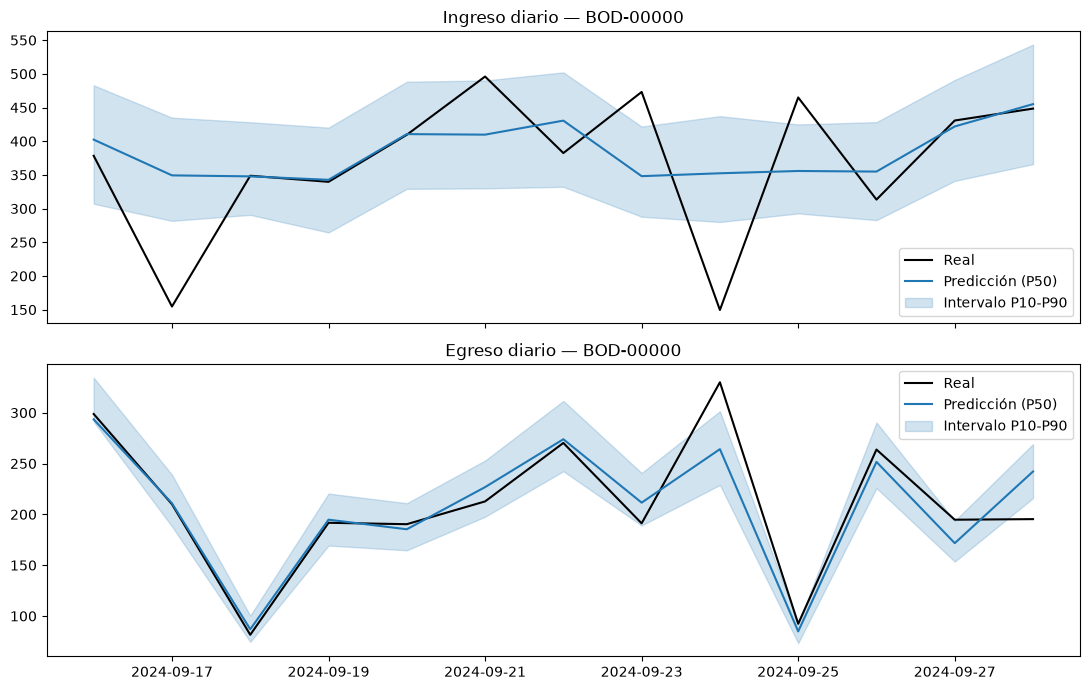

In [11]:
bodega_ejemplo = predicciones_test["bodega_id"].iloc[0]
plot_df = predicciones_test[predicciones_test["bodega_id"] == bodega_ejemplo].sort_values("fecha")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, target in zip(axes, TARGETS):
    ax.plot(plot_df["fecha"], plot_df[target], label="Real", color="black", linewidth=1.5)
    ax.plot(plot_df["fecha"], plot_df[f"{target}_pred_p50"], label="Predicción (P50)", color="#1f77b4")
    ax.fill_between(plot_df["fecha"], plot_df[f"{target}_pred_p10"], plot_df[f"{target}_pred_p90"],
                     color="#1f77b4", alpha=0.2, label="Intervalo P10-P90")
    ax.set_title(f"{target.capitalize()} diario — {bodega_ejemplo}")
    ax.legend()
plt.tight_layout()
plt.show()


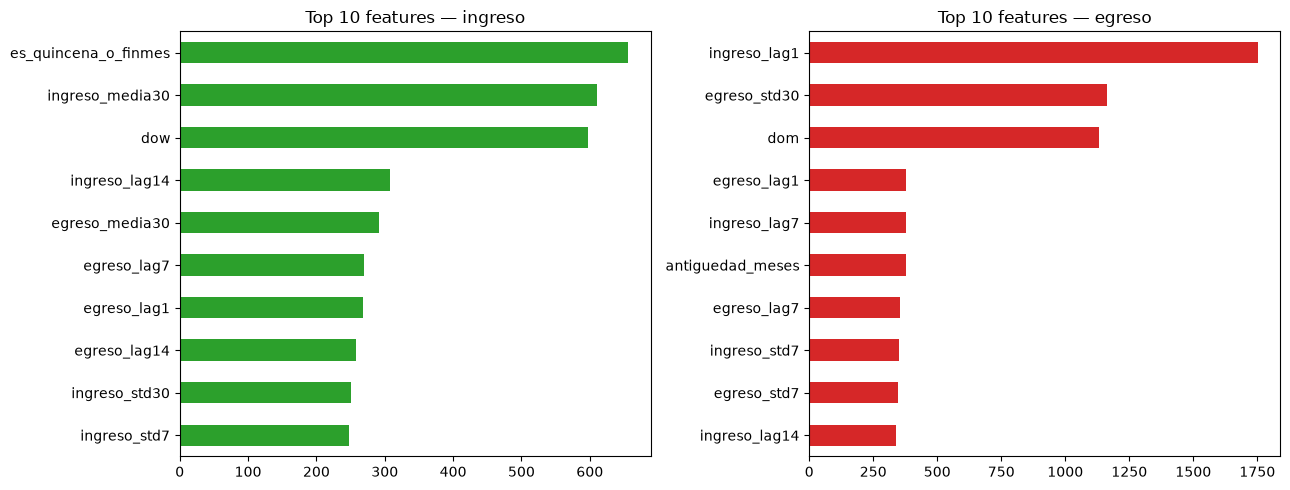

In [12]:
# 6.2 Feature importance (interpretabilidad — clave para el jurado)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, target in zip(axes, TARGETS):
    model = modelos[(target, 0.5)]
    imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=True).tail(10)
    imp.plot.barh(ax=ax, color="#2ca02c" if target == "ingreso" else "#d62728")
    ax.set_title(f"Top 10 features — {target}")
plt.tight_layout()
plt.show()


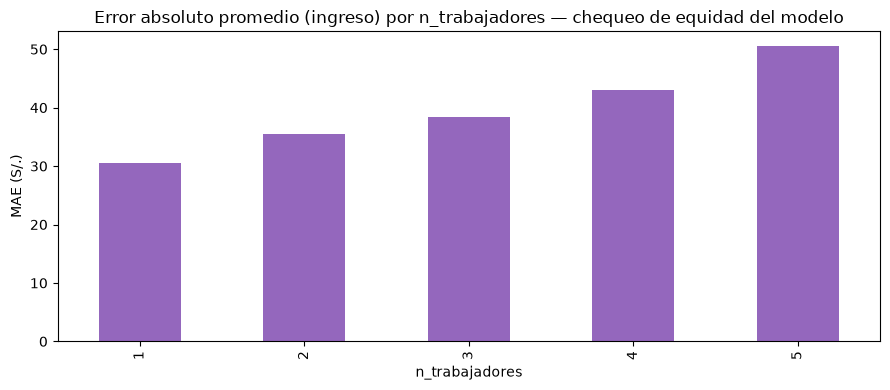

In [13]:
# 6.3 Distribución del error por n_trabajadores y rubro (robustez / equidad del modelo)
predicciones_test = predicciones_test.merge(bodegas[["bodega_id", "n_trabajadores", "rubro"]], on="bodega_id")
predicciones_test["error_abs_ingreso"] = (predicciones_test["ingreso"] - predicciones_test["ingreso_pred_p50"]).abs()

fig, ax = plt.subplots(figsize=(9, 4))
predicciones_test.groupby("n_trabajadores")["error_abs_ingreso"].mean().plot.bar(ax=ax, color="#9467bd")
ax.set_title("Error absoluto promedio (ingreso) por n_trabajadores — chequeo de equidad del modelo")
ax.set_ylabel("MAE (S/.)")
plt.tight_layout()
plt.show()

## 7. Resumen ejecutivo (para la presentación ante el jurado)

- **Dataset sintético**: 1,200 bodegas × 120 días ≈ 144K registros-día (tamaño reducido para iterar rápido en el hackathon; el pipeline escala igual a miles de bodegas y más historia), con heterogeneidad (zona, rubro, antigüedad) y estacionalidad realista documentada arriba.
- **Modelo elegido**: LightGBM quantile regression (P10/P50/P90) — simple, rápido, interpretable, y con mejor o igual desempeño que ARIMA/Prophet en benchmarks de retail (ver comparación previa).
- **Resultado**: mejora medible vs. baseline naive (ver tabla de métricas), con intervalo de confianza para comunicar incertidumbre al bodeguero.
- **Integración al MVP**: el output (`ingreso_pred_p10/p50/p90`, `egreso_pred_p10/p50/p90`) alimenta directamente el endpoint de forecast en `contract.md`, y el `caja_proyectada = ingreso_p50 - egreso_p50` es la métrica central que ve el usuario en el app.
- **Replicabilidad**: todo el pipeline (simulación → features → entrenamiento → evaluación) corre con seed fijo y es el mismo que se usaría con data real de transacciones una vez conectado el backend.
